# Tema 11 · Árboles de decisión y ensambles

Modelos que preguntan «sí o no», y por qué muchos árboles juntos aciertan más.

Este cuaderno es el tema 11 de la [ruta de aprendizaje de la OBIA](https://iabolivia.org/aprende/aprendizaje-automatico/): la teoría y los ejercicios de [la página del tema](https://iabolivia.org/aprende/aprendizaje-automatico/11-arboles-de-decision-y-ensambles/), con todo su código. Ejecuta las celdas en orden, de arriba abajo (o *Entorno de ejecución → Ejecutar todas*).

Debajo de cada celda está la salida que dio cuando se escribió el tema. Al ejecutarla, la tuya puede variar en los últimos decimales. Las actividades interactivas están en la página del tema.

# Teoría

## La pregunta

¿Conoces el juego de adivinar un personaje con preguntas de sí o no? «¿Es mujer?», «¿Tiene más de 30 años?», «¿Usa lentes?». Un buen jugador no pregunta cualquier cosa: elige la pregunta que más reduce las posibilidades, y según la respuesta decide cuál es la siguiente.

Un **árbol de decisión** es un modelo que juega a eso con los datos. En lugar de una fórmula con pesos, como la regresión lineal o la logística, aprende una lista de preguntas encadenadas: «¿el pasajero es mujer? Si sí, ¿viajaba en primera o segunda clase?…». Al final de cada camino hay una predicción. Es uno de los modelos más fáciles de leer, y hay un giro: un árbol solo se equivoca bastante, pero **cientos de árboles juntos** están entre los mejores modelos que existen para datos en tablas.

En este tema vas a:

- entender cómo un árbol elige cada pregunta con la **impureza de Gini** (o la **entropía**) y la **ganancia**;
- programar desde cero, con NumPy, el mejor corte de una variable;
- controlar el sobreajuste de un árbol con `max_depth` y `min_samples_leaf`;
- explicar **bagging** y **random forest** como el promedio de muchos árboles distintos;
- explicar **gradient boosting** como una cadena de árboles en la que cada uno corrige los errores de los anteriores;
- comparar los modelos y medir qué variables importan con la **importancia por permutación**.

Necesitas lo de los temas anteriores: dividir en entrenamiento, validación y prueba, y la validación cruzada (tema 7), la exactitud como métrica (temas 8 y 9) y armar un `Pipeline` con `ColumnTransformer` (tema 10).

## Actividad: corta el plano

Hay puntos de dos clases, tinta (círculos) y coral (cuadrados). Tu trabajo es separarlos solo con **cortes rectos**: líneas verticales u horizontales. Cada corte divide una región en dos, y cada lado puede volver a cortarse. Lo que vas armando, sin saberlo, es un árbol de decisión.

> **Actividad interactiva:** está en la [página del tema](https://iabolivia.org/aprende/aprendizaje-automatico/11-arboles-de-decision-y-ensambles/teoria/). Ábrela en el navegador para usarla.
Prueba esto, en orden:

1. Elige «Vertical», pasa el puntero sobre el plano (o mueve el deslizador de posición) y mira cómo cambian el Gini de cada lado y la **ganancia**. Busca el corte con la ganancia más grande y córtalo.
2. Sigue cortando las regiones que todavía mezclan colores. ¿Cuántos cortes necesitas para que cada región quede de un solo color?
3. Pulsa «Empezar de nuevo» y luego «Mejor corte» en la región entera. ¿La computadora eligió el mismo corte que tú?
4. Pulsa «Árbol automático». El árbol corta hasta que cada región es pura. Mira las regiones angostas que encierran a un solo punto: ¿te parecen una regla que serviría para puntos nuevos?
5. Mueve el deslizador «Árboles del bosque». Con 1 árbol ves un solo árbol entrenado con una muestra al azar de los puntos; con 25, el promedio de 25 árboles distintos. ¿Cómo cambia la frontera?

La idea del tema completa está aquí: **un árbol corta el plano en rectángulos eligiendo cada vez el corte que más «limpia» las regiones; uno solo memoriza detalles, y muchos promediados dibujan una frontera más suave y más confiable.**

## Los datos: el Titanic

Vamos a trabajar con los pasajeros del Titanic, el barco que se hundió en 1912. La tabla trae, para 891 pasajeros, la clase en que viajaban, el sexo, la edad, cuántos familiares iban con ellos, la tarifa que pagaron, el puerto donde subieron y si sobrevivieron. Viene con la librería seaborn. Es un caso real y triste: los números que vas a ver son personas. Nos sirve porque las reglas que va a encontrar el árbol cuentan una historia que se puede comprobar.

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

titanic = sns.load_dataset("titanic")

# Las columnas que vamos a usar, con nombres en español
columnas = {"pclass": "clase", "sex": "sexo", "age": "edad",
            "sibsp": "hermanos_pareja", "parch": "padres_hijos",
            "fare": "tarifa", "embarked": "puerto"}
X = titanic[list(columnas)].rename(columns=columnas)
X["sexo"] = X["sexo"].map({"male": "hombre", "female": "mujer"})
y = titanic["survived"]               # 1 = sobrevivió, 0 = murió

print(X.shape)
print(X.head(3))
print("Faltantes:", X.isna().sum()[X.isna().sum() > 0].to_dict())
print(f"Sobrevivió el {y.mean():.1%} de los pasajeros")

(891, 7)
   clase    sexo  edad  hermanos_pareja  padres_hijos   tarifa puerto
0      3  hombre  22.0                1             0   7.2500      S
1      1   mujer  38.0                1             0  71.2833      C
2      3   mujer  26.0                0             0   7.9250      S
Faltantes: {'edad': 177, 'puerto': 2}
Sobrevivió el 38.4% de los pasajeros


Hay edades que faltan y dos pasajeros sin puerto. Antes de entrenar, separamos un conjunto de **prueba** que no vamos a mirar hasta el final (tema 7) y armamos una preparación del mismo tipo que la del tema 10, pero más sencilla (no usamos `crear_pipeline_titanic`): las columnas van con nombres en español y sin las variables nuevas, para que las preguntas del árbol se lean fácil, y no escalamos (enseguida verás por qué). Es un `ColumnTransformer` que imputa la mediana en las columnas numéricas y, en las categóricas, imputa el valor más frecuente y las pasa a columnas one-hot.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.base import clone

X_ent, X_prueba, y_ent, y_prueba = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=0)

numericas = ["clase", "edad", "hermanos_pareja", "padres_hijos", "tarifa"]
categoricas = ["sexo", "puerto"]
categoricas_a_numeros = make_pipeline(
    SimpleImputer(strategy="most_frequent"),
    # drop="if_binary": «sexo» queda en una sola columna, sexo_mujer
    OneHotEncoder(drop="if_binary", handle_unknown="ignore",
                  sparse_output=False))
preparar = ColumnTransformer(
    [("num", SimpleImputer(strategy="median"), numericas),
     ("cat", categoricas_a_numeros, categoricas)],
    verbose_feature_names_out=False)

def con_preparacion(modelo):
    """Un Pipeline: preparar los datos y después el modelo."""
    return Pipeline([("preparar", clone(preparar)), ("modelo", modelo)])

A = preparar.fit_transform(X_ent)     # solo con entrenamiento
nombres = preparar.get_feature_names_out()
y_arr = y_ent.to_numpy()
print(len(X_ent), "pasajeros para entrenar,",
      len(X_prueba), "para la prueba final")
print("Columnas:", ", ".join(nombres[:5]))
print("         ", ", ".join(nombres[5:]))

668 pasajeros para entrenar, 223 para la prueba final
Columnas: clase, edad, hermanos_pareja, padres_hijos, tarifa
          sexo_mujer, puerto_C, puerto_Q, puerto_S


Fíjate en algo que **no** hicimos: escalar. Un árbol solo pregunta «¿esta variable es menor que tal número?», y la respuesta no cambia si la variable se mide en bolivianos o en dólares, en años o en meses. Por eso a los árboles no les importa la escala, a diferencia de k-NN o la regresión logística.

## ¿Qué es un buen corte? La impureza de Gini

Un árbol empieza con todos los pasajeros juntos y busca **una pregunta de sí o no** que los separe en dos grupos. Una pregunta es buena si los grupos que deja son lo más «puros» posible: idealmente, en uno solo sobrevivientes y en el otro solo no sobrevivientes.

Para medir qué tan mezclado está un grupo se usa la **impureza de Gini**. Si en el grupo una fracción *p*<sub>k</sub> de los ejemplos es de la clase *k*:

$$\text{Gini} = 1 - \sum_{k} {p}_{k}^{2}$$

Tiene una lectura muy concreta: es la probabilidad de equivocarte si tomas un ejemplo del grupo al azar y le pones una etiqueta también al azar, sorteada con las proporciones del grupo. Con dos clases:

- Un grupo **puro** (todos de la misma clase) tiene Gini = 1 − 1² = **0**.
- Un grupo **mitad y mitad** tiene Gini = 1 − 0,5² − 0,5² = **0,5**, el máximo con dos clases.

In [ ]:
def gini(etiquetas):
    """Impureza de Gini de un grupo de etiquetas."""
    _, cuentas = np.unique(etiquetas, return_counts=True)
    p = cuentas / len(etiquetas)      # proporción de cada clase
    return 1 - np.sum(p ** 2)

print("Puro:          ", gini([1, 1, 1, 1]))
print("Mitad y mitad: ", gini([0, 1, 0, 1]))
print("Tres a uno:    ", gini([0, 0, 0, 1]))
print(f"Titanic entero: {gini(y_arr):.3f}")

Puro:           0.0
Mitad y mitad:  0.5
Tres a uno:     0.375
Titanic entero: 0.473


Un corte divide un grupo en dos lados, izquierdo y derecho. La impureza después del corte es el promedio de las dos impurezas, **ponderado** por cuántos ejemplos quedan en cada lado (un lado con 3 pasajeros no puede pesar lo mismo que uno con 300). La **ganancia** es cuánto bajó la impureza:

$$\text{ganancia} = \text{Gini} ( \text{padre} ) - ( \frac{{n}_{\text{izq}}}{n} \text{Gini} ( \text{izq} ) + \frac{{n}_{\text{der}}}{n} \text{Gini} ( \text{der} ) )$$

El árbol elige, entre todas las preguntas posibles, la de **mayor ganancia**. Es lo que hacías en la actividad al buscar el corte con el número más grande.

**La entropía, la otra medida.** En lugar de Gini se puede usar la **entropía** de la teoría de la información. La idea: mide cuánta «sorpresa» hay, en promedio, al descubrir la clase de un pasajero del grupo; es 0 si todos son de la misma clase y crece cuanto más mezclado está el grupo. Usa un logaritmo nuevo, en base 2: log₂ *x* responde «¿a qué potencia hay que elevar 2 para obtener *x*?», o sea, cuántas veces se divide *x* entre 2 hasta llegar a 1. Por ejemplo, log₂ 8 = 3 (8 → 4 → 2 → 1) y log₂ 0,5 = −1 (porque 2<sup>−1</sup> = 0,5). En NumPy es `np.log2`. Por usar base 2, la entropía se mide en **bits**:

$$H = - \sum_{k} {p}_{k} \cdot {\log}_{2} {p}_{k}$$

También vale 0 en un grupo puro, y con dos clases llega a 1 bit en el grupo mitad y mitad: −(0,5 · log₂ 0,5 + 0,5 · log₂ 0,5) = −(−0,5 − 0,5) = 1, la misma incertidumbre que lanzar una moneda. La ganancia calculada con la entropía se llama **ganancia de información**. En la práctica, Gini y entropía casi siempre eligen los mismos cortes; scikit-learn usa Gini por defecto (`criterion="gini"`) y acepta `criterion="entropy"`. En los ejercicios vas a comparar las dos.

## El mejor corte, desde cero

Para una variable numérica, las preguntas posibles son «¿*x* ≤ *u*?» para distintos umbrales *u*. No hace falta probar infinitos umbrales: basta con los puntos medios entre valores distintos consecutivos, porque entre dos valores vecinos cualquier umbral separa a los pasajeros igual. La función prueba todos y se queda con el de menor impureza ponderada, que es el de mayor ganancia.

In [ ]:
def mejor_corte(x, etiquetas):
    """El umbral u de la pregunta «¿x <= u?» con mayor ganancia.

    Devuelve el mejor umbral, su ganancia, y todos los umbrales
    probados con su impureza ponderada (para graficarlos).
    """
    valores = np.unique(x)            # ordenados y sin repetir
    umbrales = (valores[:-1] + valores[1:]) / 2
    n = len(etiquetas)
    ponderadas = []
    for u in umbrales:
        izq = etiquetas[x <= u]
        der = etiquetas[x > u]
        ponderadas.append((len(izq) * gini(izq)
                           + len(der) * gini(der)) / n)
    ponderadas = np.array(ponderadas)
    k = np.argmin(ponderadas)
    ganancia = gini(etiquetas) - ponderadas[k]
    return umbrales[k], ganancia, umbrales, ponderadas

# El mejor corte de cada columna, para la raíz del árbol
for j, nombre in enumerate(nombres):
    u, ganancia, _, _ = mejor_corte(A[:, j], y_arr)
    print(f"{nombre:16s} ¿<= {u:6.2f}?   ganancia = {ganancia:.3f}")

clase            ¿<=   2.50?   ganancia = 0.059
edad             ¿<=   0.96?   ganancia = 0.007
hermanos_pareja  ¿<=   0.50?   ganancia = 0.006
padres_hijos     ¿<=   0.50?   ganancia = 0.010
tarifa           ¿<=  50.74?   ganancia = 0.049
sexo_mujer       ¿<=   0.50?   ganancia = 0.145
puerto_C         ¿<=   0.50?   ganancia = 0.010
puerto_Q         ¿<=   0.50?   ganancia = 0.000
puerto_S         ¿<=   0.50?   ganancia = 0.008


La pregunta ganadora es la del sexo, con mucha diferencia: «¿`sexo_mujer` ≤ 0,5?», es decir, «¿es hombre?». La segunda es la clase del pasaje. Es lo que cuenta la historia: en la evacuación se priorizó a las mujeres y a los niños, y los pasajeros de primera clase tenían los camarotes más cerca de los botes salvavidas.

El árbol no se detiene ahí. Repite **la misma búsqueda dentro de cada lado**. Mira lo que pasa con la edad, pero ahora solo entre los hombres:

Entre los hombres: ¿edad <= 13?   ganancia = 0.022
Hombres de 13 años o menos: 30, sobrevivió el 57%


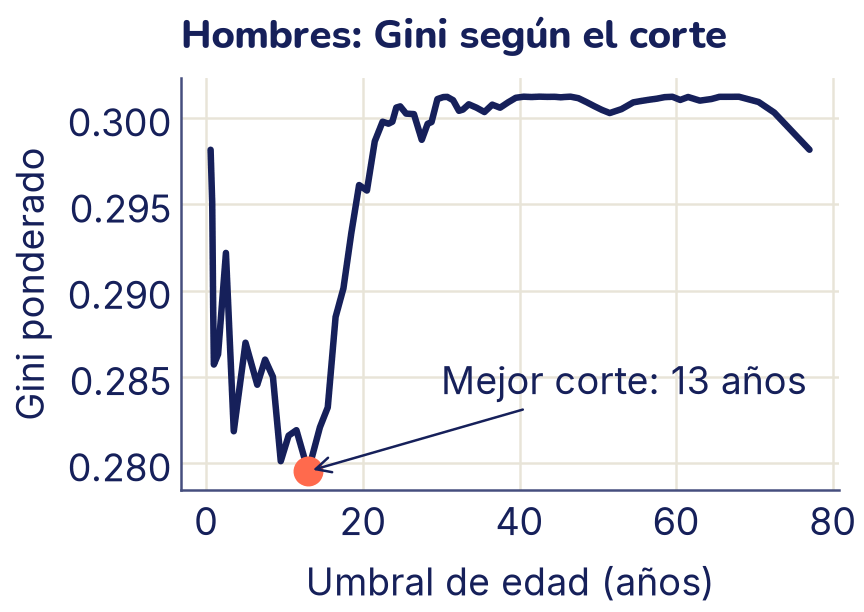

In [ ]:
hombres = A[:, list(nombres).index("sexo_mujer")] == 0
edad_h = A[hombres, list(nombres).index("edad")]
u, ganancia, umbrales, ponderadas = mejor_corte(edad_h, y_arr[hombres])
print(f"Entre los hombres: ¿edad <= {u:g}?   ganancia = {ganancia:.3f}")
menores = y_arr[hombres][edad_h <= u]
print(f"Hombres de {u:g} años o menos: {len(menores)},"
      f" sobrevivió el {menores.mean():.0%}")

plt.plot(umbrales, ponderadas, color="C0")
plt.scatter([u], [ponderadas.min()], color="C1", s=120, zorder=3)
# Un texto con flecha que señala el punto
plt.annotate(f"Mejor corte: {u:g} años", xy=(u, ponderadas.min()),
             xytext=(30, 0.284),
             arrowprops=dict(arrowstyle="->", color="C0"))
plt.xlabel("Umbral de edad (años)")
plt.ylabel("Gini ponderado")
plt.title("Hombres: Gini según el corte")
plt.show()

Entre los hombres, la edad casi no separa nada, salvo por un pozo muy claro: los **niños**. Esa pregunta no aparecía entre las mejores de la raíz (con todos los pasajeros juntos, la edad sola casi no ayuda), pero dentro de un grupo puede ser la mejor. Así trabaja un árbol: cada pregunta se elige mirando solo a los ejemplos que llegaron a ese lugar. Este procedimiento, que elige el mejor corte en cada paso sin pensar en los siguientes, se llama **voraz** (*greedy*).

## Un árbol con scikit-learn

`DecisionTreeClassifier` hace exactamente esto, para todas las columnas y en cada rama. Lo ponemos dentro de nuestro pipeline y le limitamos la profundidad a 2 (dos preguntas como máximo) para poder dibujarlo. `plot_tree` lo dibuja; el bucle de después solo cambia los colores de las cajas y traduce «True» y «False».

Exactitud en entrenamiento: 0.801


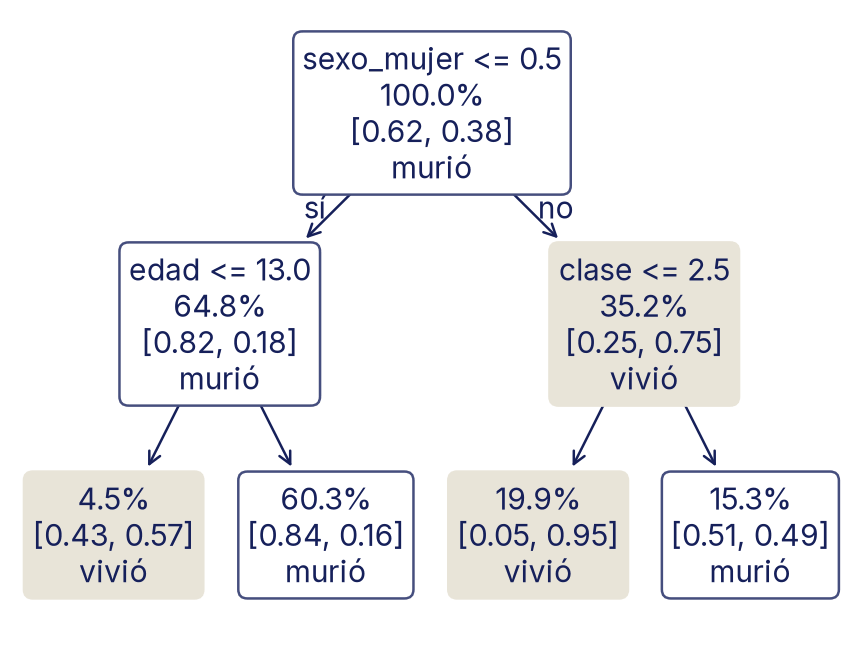

In [ ]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

arbol2 = con_preparacion(DecisionTreeClassifier(max_depth=2,
                                                random_state=0))
arbol2.fit(X_ent, y_ent)

plt.figure(figsize=(4.8, 3.6))
cajas = plot_tree(arbol2["modelo"], feature_names=nombres,
                  class_names=["murió", "vivió"], label="none",
                  impurity=False, proportion=True, precision=2,
                  rounded=True, fontsize=12)
for caja in cajas:
    texto = caja.get_text().strip()
    if texto in ("True", "False"):
        caja.set_text("sí" if texto == "True" else "no")
    elif texto.endswith("vivió"):
        caja.get_bbox_patch().set(facecolor="C3", edgecolor="C3")
    else:
        caja.get_bbox_patch().set(facecolor="white", edgecolor="C2")
plt.show()

print(f"Exactitud en entrenamiento: {arbol2.score(X_ent, y_ent):.3f}")

Cómo se lee cada caja:

- La primera línea es la **pregunta** (las hojas, abajo, no tienen pregunta). Si la respuesta es sí, se sigue por la izquierda.
- El porcentaje es la parte de los pasajeros de entrenamiento que llega a esa caja.
- El par de números es la proporción de cada clase en la caja: [murió, vivió].
- La última línea es la **predicción**: la clase mayoritaria de la caja.

Son los mismos cortes que encontraste con `mejor_corte`: el sexo en la raíz y, entre los hombres, la edad de 13 años. Para predecir un pasajero nuevo se lo hace bajar por el árbol, respondiendo las preguntas, hasta llegar a una **hoja**. La probabilidad que da `predict_proba` es la proporción de la hoja: una mujer de primera clase cae en la hoja con [0,05, 0,95] y recibe 95 % de probabilidad de sobrevivir.

En el plano de la actividad, cada pregunta es un corte recto y cada hoja es un rectángulo. Con muchas variables pasa lo mismo, en más dimensiones: un árbol divide el espacio en cajas y en cada caja predice una constante.

## Profundidad y sobreajuste

¿Qué pasa si dejamos crecer el árbol sin límite? Sigue cortando hasta que cada hoja es pura, aunque tenga un solo ejemplo. Para verlo en un dibujo usamos datos **sintéticos** de dos variables, las «dos lunas» de `make_moons`, con bastante ruido.

Profundidad  1:  2 hojas, entrenamiento 0.83, validación 0.78
Profundidad  3:  6 hojas, entrenamiento 0.89, validación 0.89
Profundidad 10: 20 hojas, entrenamiento 1.00, validación 0.85


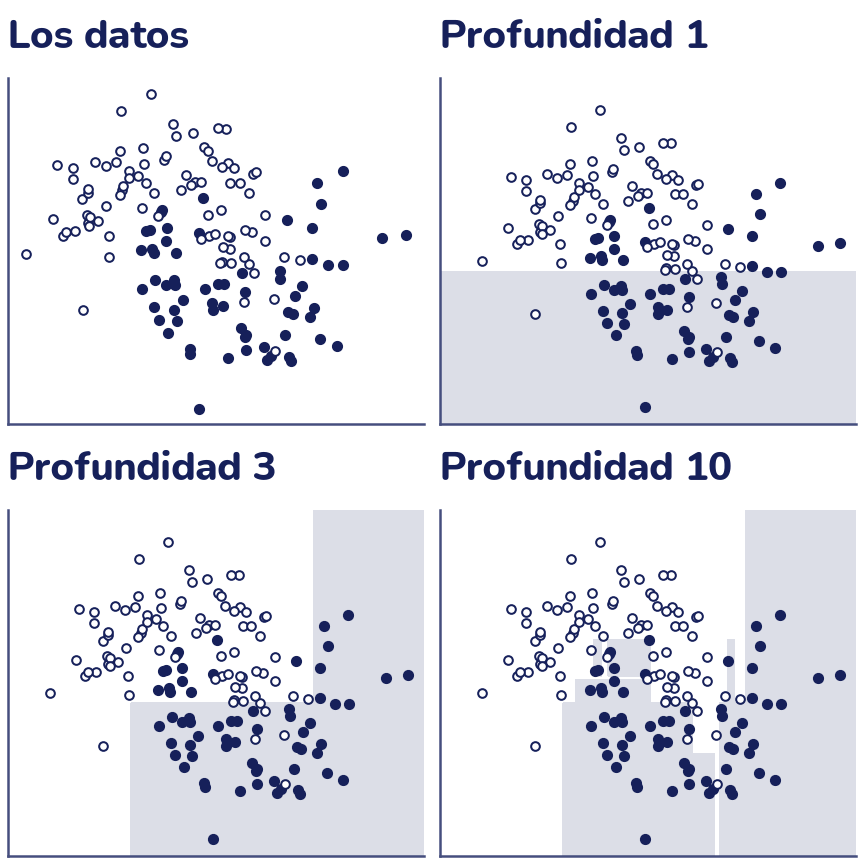

In [ ]:
from sklearn.datasets import make_moons

X2, y2 = make_moons(n_samples=300, noise=0.3, random_state=0)
X2_ent, X2_val, y2_ent, y2_val = train_test_split(
    X2, y2, test_size=0.5, random_state=0)

# Una rejilla fina para pintar la región de cada clase
xx, yy = np.meshgrid(np.linspace(-2, 3, 300), np.linspace(-1.5, 2, 300))
rejilla = np.column_stack([xx.ravel(), yy.ravel()])

def dibujar_puntos(eje):
    """Clase 1: puntos llenos. Clase 0: puntos huecos."""
    # .T deja las dos columnas como filas, y * las pasa por separado
    # a scatter, como x e y
    eje.scatter(*X2_ent[y2_ent == 1].T, s=12, color="C0")
    eje.scatter(*X2_ent[y2_ent == 0].T, s=12, facecolors="white",
                edgecolors="C0", linewidths=0.8)
    eje.set_xticks([])
    eje.set_yticks([])

fig, ejes = plt.subplots(2, 2, figsize=(4.8, 4.8))
dibujar_puntos(ejes[0, 0])
ejes[0, 0].set_title("Los datos")
for eje, prof in zip([ejes[0, 1], ejes[1, 0], ejes[1, 1]], [1, 3, 10]):
    a = DecisionTreeClassifier(max_depth=prof, random_state=0)
    a.fit(X2_ent, y2_ent)
    z = a.predict(rejilla).reshape(xx.shape)
    # Se pinta solo la región donde el árbol predice la clase 1
    eje.contourf(xx, yy, z, levels=[0.5, 1.5], colors=["C0"], alpha=0.15)
    dibujar_puntos(eje)
    eje.set_title(f"Profundidad {prof}")
    print(f"Profundidad {prof:2d}: {a.get_n_leaves():2d} hojas,"
          f" entrenamiento {a.score(X2_ent, y2_ent):.2f},"
          f" validación {a.score(X2_val, y2_val):.2f}")
plt.show()

Las fronteras de un árbol son siempre **escaleras**: líneas verticales y horizontales. Con profundidad 1 hay un solo corte y el modelo es demasiado simple (**subajuste**). Con profundidad 10, el árbol acierta todos los puntos de entrenamiento, pero lo logra dibujando rectángulos chiquitos alrededor de puntos que están del lado «equivocado» por el ruido: memoriza (**sobreajuste**), y en validación le va peor que con profundidad 3. Es la «U» del tema 7, otra vez.

Los dos frenos más usados son:

- **`max_depth`**: el número máximo de preguntas en cualquier camino.
- **`min_samples_leaf`**: cuántos ejemplos debe tener cada hoja como mínimo. Con 10, el árbol no puede crear una hoja para un solo pasajero raro.

Busquemos los dos con validación cruzada en el Titanic. Como el árbol está dentro del pipeline, en cada pliegue la imputación se calcula solo con la parte de entrenamiento, sin fuga de datos.

In [ ]:
from sklearn.model_selection import cross_val_score

print("max_depth   entrenamiento   validación cruzada")
for prof in [1, 2, 3, 4, 6, 8, None]:
    modelo = con_preparacion(DecisionTreeClassifier(max_depth=prof,
                                                    random_state=0))
    vc = cross_val_score(modelo, X_ent, y_ent, cv=5).mean()
    ent = modelo.fit(X_ent, y_ent).score(X_ent, y_ent)
    print(f"{str(prof):>9s}   {ent:13.3f}   {vc:18.3f}")

print("\nmin_samples_leaf   entrenamiento   validación cruzada")
for hoja in [1, 5, 10, 20]:
    modelo = con_preparacion(DecisionTreeClassifier(
        min_samples_leaf=hoja, random_state=0))
    vc = cross_val_score(modelo, X_ent, y_ent, cv=5).mean()
    ent = modelo.fit(X_ent, y_ent).score(X_ent, y_ent)
    print(f"{hoja:16d}   {ent:13.3f}   {vc:18.3f}")

max_depth   entrenamiento   validación cruzada
        1           0.792                0.792
        2           0.801                0.789
        3           0.843                0.819
        4           0.847                0.819
        6           0.874                0.811
        8           0.910                0.793
     None           0.982                0.771

min_samples_leaf   entrenamiento   validación cruzada
               1           0.982                0.771
               5           0.885                0.823
              10           0.870                0.805
              20           0.828                0.804


Sin límites (`None`), el árbol acierta casi todo en entrenamiento y es de los peores en validación. Lo mejor está en un punto medio: profundidad 3 o 4, o un mínimo de 5 pasajeros por hoja.

## La varianza de un árbol

Un árbol profundo tiene otro problema, más escondido: es **inestable**. Si cambias un poco los datos de entrenamiento, las primeras preguntas pueden cambiar, y con ellas todas las de abajo. Para verlo, entrenemos cinco árboles sin límite de profundidad, cada uno con una **muestra bootstrap** de los pasajeros: una muestra del mismo tamaño, sacada **con reposición** (un pasajero puede salir dos o tres veces y otro ninguna).

In [ ]:
rng = np.random.default_rng(0)
# Un pliegue de validación dentro del entrenamiento
A_e, A_v, y_e, y_v = train_test_split(A, y_arr, test_size=0.25,
                                      stratify=y_arr, random_state=1)
predicciones = []
for i in range(5):
    muestra = rng.integers(0, len(A_e), size=len(A_e))  # bootstrap
    a = DecisionTreeClassifier(random_state=0)
    a.fit(A_e[muestra], y_e[muestra])
    predicciones.append(a.predict(A_v))
    acierto = np.mean(predicciones[-1] == y_v)
    print(f"Árbol {i + 1}: ve {len(np.unique(muestra))} de"
          f" {len(A_e)} pasajeros, validación {acierto:.3f}")

predicciones = np.array(predicciones)
# Un pasajero tiene desacuerdo si no todos los árboles dicen lo mismo
distintos = predicciones.min(axis=0) != predicciones.max(axis=0)
desacuerdo = np.mean(distintos)
print(f"Los 5 árboles no coinciden en el {desacuerdo:.0%}"
      " de los pasajeros de validación")
votos = (predicciones.mean(axis=0) > 0.5).astype(int)
print(f"Votación de los 5 árboles: validación {np.mean(votos == y_v):.3f}")

Árbol 1: ve 316 de 501 pasajeros, validación 0.743
Árbol 2: ve 308 de 501 pasajeros, validación 0.743
Árbol 3: ve 316 de 501 pasajeros, validación 0.766
Árbol 4: ve 313 de 501 pasajeros, validación 0.784
Árbol 5: ve 314 de 501 pasajeros, validación 0.754
Los 5 árboles no coinciden en el 37% de los pasajeros de validación
Votación de los 5 árboles: validación 0.778


Cada árbol ve cerca de dos tercios de los pasajeros distintos (el resto de su muestra son repetidos), y aunque los cinco aciertan parecido, **no se equivocan en los mismos pasajeros**: discrepan en más de un tercio de los casos. Esa es la **varianza** del modelo: el resultado depende mucho de qué datos le tocaron. Y aparece la idea clave de los ensambles: si cada árbol se equivoca en lugares distintos, al **votar** muchos de ellos los errores se compensan en parte. Con solo cinco árboles, la votación (0,778) ya acierta más que el promedio de los cinco por separado (0,758).

## Bagging y random forest

**Bagging** (de *bootstrap aggregating*) es justo lo que hicimos: entrenar muchos árboles, cada uno con su muestra bootstrap, y predecir por votación (o promediando sus probabilidades). Cada árbol se deja crecer profundo, con poco sesgo y mucha varianza; el promedio conserva el poco sesgo y baja la varianza.

El **random forest** (bosque aleatorio) agrega una vuelta más: en **cada corte**, cada árbol solo puede elegir entre un subconjunto de variables sorteado al azar (en clasificación, por defecto, la raíz cuadrada del número de variables). Así los árboles se parecen menos entre sí. Si una variable domina, como el sexo, en el bagging casi todos los árboles empiezan con la misma pregunta y se equivocan parecido; en el bosque, algunos árboles se ven obligados a empezar por otra, y el promedio gana.

Otra ventaja del bootstrap: cada árbol deja afuera cerca de un tercio de los pasajeros. Esos pasajeros «fuera de la bolsa» (*out of bag*, OOB) sirven como validación gratis: cada pasajero se predice solo con los árboles que no lo vieron. Es el **error OOB**.

In [ ]:
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier

bagging = con_preparacion(BaggingClassifier(
    DecisionTreeClassifier(), n_estimators=200, random_state=0))
bosque = con_preparacion(RandomForestClassifier(
    n_estimators=200, oob_score=True, random_state=0))

for nombre, modelo in [("Bagging", bagging), ("Random forest", bosque)]:
    vc = cross_val_score(modelo, X_ent, y_ent, cv=5).mean()
    print(f"{nombre:14s} validación cruzada = {vc:.3f}")

bosque.fit(X_ent, y_ent)
print(f"Random forest, exactitud OOB: {bosque['modelo'].oob_score_:.3f}")

Bagging        validación cruzada = 0.814
Random forest  validación cruzada = 0.813
Random forest, exactitud OOB: 0.808


Los dos ensambles superan con claridad al árbol sin límites (0,771) y quedan cerca del mejor árbol podado, sin que hayamos elegido ninguna profundidad. La exactitud OOB se parece a la de la validación cruzada, y salió de un solo entrenamiento.

En el plano de las lunas, el bosque se ve así. A cada árbol le pedimos al menos 5 puntos por hoja, y sombreamos la probabilidad de la clase 1 en cuatro bandas: más oscuro, más árboles votan por ella.

Bosque: entrenamiento 0.95, validación 0.90


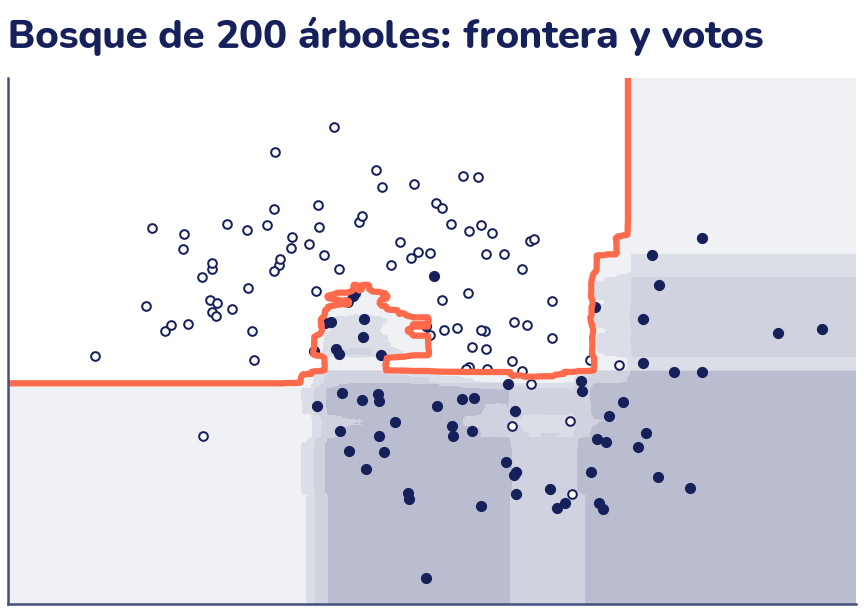

In [ ]:
bosque2 = RandomForestClassifier(n_estimators=200, min_samples_leaf=5,
                                 random_state=0)
bosque2.fit(X2_ent, y2_ent)
prob = bosque2.predict_proba(rejilla)[:, 1].reshape(xx.shape)

fig, eje = plt.subplots()
for desde in [0.5, 0.625, 0.75, 0.875]:
    eje.contourf(xx, yy, prob, levels=[desde, 1.01], colors=["C0"],
                 alpha=0.08)
eje.contour(xx, yy, prob, levels=[0.5], colors=["C1"], linewidths=2.5)
dibujar_puntos(eje)
eje.set_title("Bosque de 200 árboles: frontera y votos")
plt.show()

print(f"Bosque: entrenamiento {bosque2.score(X2_ent, y2_ent):.2f},"
      f" validación {bosque2.score(X2_val, y2_val):.2f}")

La frontera todavía tiene escalones (cada árbol corta en rectángulos), pero ya no encierra puntos sueltos como el árbol de profundidad 10, y en validación acierta 0,90, más que cualquiera de los árboles solos de la figura anterior. Las bandas muestran algo que un árbol solo no da: dónde el modelo está seguro (bandas oscuras, casi todos los árboles de acuerdo) y dónde duda (bandas claras, cerca de la frontera). Es lo que viste en la actividad al subir el número de árboles.

## Boosting: árboles que corrigen errores

El bagging entrena los árboles **en paralelo**, cada uno por su cuenta. El **boosting** los entrena **en cadena**: cada árbol nuevo se dedica a corregir lo que los anteriores todavía hacen mal. Los árboles de boosting son chiquitos (profundidad 2 o 3): ninguno sabe mucho, pero la suma sí.

La idea se ve más clara en regresión. Tomemos unos datos **sintéticos**: una onda con ruido. El **gradient boosting** con error cuadrático hace esto:

1. Empieza prediciendo el promedio de *y* para todos.
2. Calcula los **residuos**, *y* menos lo predicho: lo que falta corregir.
3. Entrena un árbol chico para predecir esos residuos.
4. Suma a la predicción lo que dice ese árbol, multiplicado por una **tasa de aprendizaje** pequeña.
5. Vuelve al paso 2.

¿Por qué «gradient»? Mira la pérdida de un solo punto, (*y* − *ŷ*)², donde *ŷ* es lo que predice el modelo para ese punto, y piensa en *ŷ* como si fuera el parámetro. Su derivada respecto de *ŷ* es −2(*y* − *ŷ*): menos dos veces el residuo. Bajar por el gradiente es moverse en sentido contrario, o sea, sumarle a *ŷ* algo proporcional al residuo *y* − *ŷ*. Eso es justo lo que hace cada árbol: un paso de **descenso de gradiente**, como en el tema 6, pero en lugar de mover dos parámetros mueve directamente las predicciones.

Después de   1 árboles: MSE = 0.448
Después de   5 árboles: MSE = 0.234
Después de  50 árboles: MSE = 0.026
Después de 100 árboles: MSE = 0.017


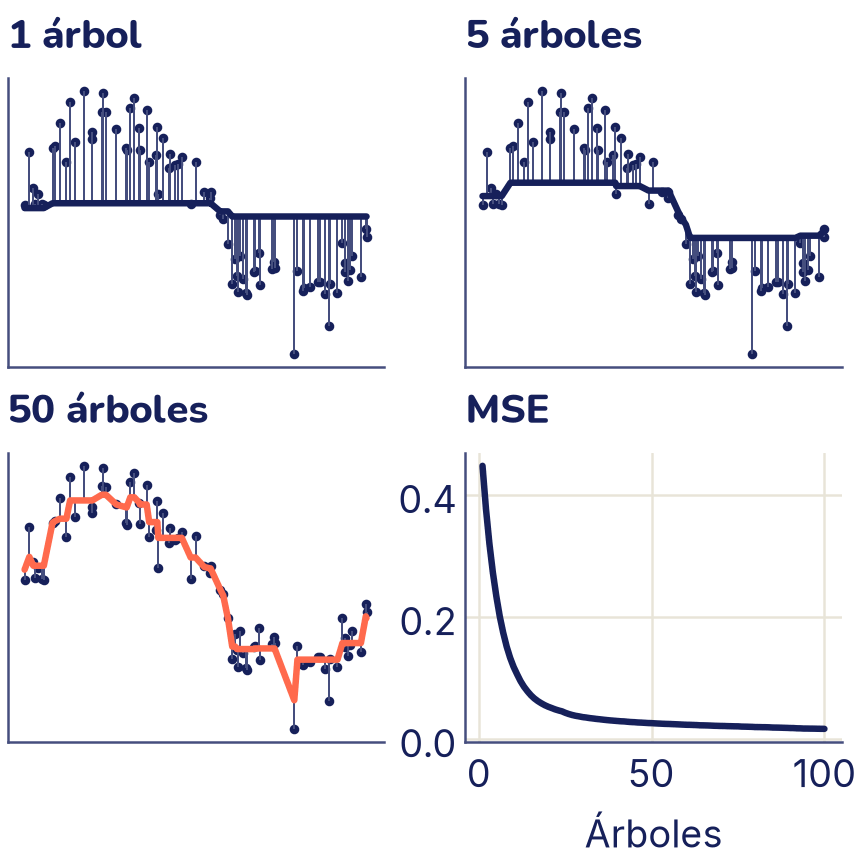

In [ ]:
from sklearn.tree import DecisionTreeRegressor

rng = np.random.default_rng(0)
x = np.sort(rng.uniform(0, 6, 80))
onda = np.sin(x) + rng.normal(0, 0.25, 80)   # datos sintéticos
Xx = x.reshape(-1, 1)

tasa = 0.1
pred = np.full(len(x), onda.mean())   # paso 1: el promedio
historia = {}                         # predicción tras algunos árboles
errores = []
for m in range(1, 101):
    residuos = onda - pred            # paso 2: lo que falta
    a = DecisionTreeRegressor(max_depth=2, random_state=0)
    a.fit(Xx, residuos)               # paso 3: aprender los residuos
    pred = pred + tasa * a.predict(Xx)  # paso 4: corregir un poco
    errores.append(np.mean((onda - pred) ** 2))
    if m in (1, 5, 50):
        historia[m] = pred.copy()

for m in (1, 5, 50, 100):
    print(f"Después de {m:3d} árboles: MSE = {errores[m - 1]:.3f}")

fig, ejes = plt.subplots(2, 2, figsize=(4.8, 4.8))
for eje, m in zip([ejes[0, 0], ejes[0, 1], ejes[1, 0]], (1, 5, 50)):
    eje.vlines(x, historia[m], onda, color="C2", linewidth=0.8)
    eje.scatter(x, onda, s=8, color="C0")
    eje.plot(x, historia[m], color="C1" if m == 50 else "C0")
    eje.set_title(f"{m} {'árbol' if m == 1 else 'árboles'}")
    eje.set_xticks([])
    eje.set_yticks([])
ejes[1, 1].plot(range(1, 101), errores, color="C0")
ejes[1, 1].set_title("MSE")
ejes[1, 1].set_xlabel("Árboles")
plt.show()

Con un árbol, la predicción apenas se movió del promedio, porque la tasa de 0,1 solo deja pasar una décima parte de cada corrección. A los 5 árboles empieza a aparecer la onda, y a los 50 los residuos son cortos. `GradientBoostingRegressor` de scikit-learn hace exactamente este bucle:

In [ ]:
from sklearn.ensemble import GradientBoostingRegressor

gb = GradientBoostingRegressor(n_estimators=100, learning_rate=0.1,
                               max_depth=2, random_state=0)
gb.fit(Xx, onda)
diferencia = np.abs(gb.predict(Xx) - pred).max()
print(f"MSE de scikit-learn: {np.mean((onda - gb.predict(Xx)) ** 2):.3f}")
print(f"Mayor diferencia con nuestro bucle: {diferencia:.1e}")

MSE de scikit-learn: 0.017
Mayor diferencia con nuestro bucle: 2.2e-16


Dos hiperparámetros van de la mano:

- **`learning_rate`**: cuánto de cada corrección se suma. Más chica, más árboles hacen falta, pero el resultado suele generalizar mejor.
- **`n_estimators`**: cuántos árboles. A diferencia del bosque, en boosting **demasiados árboles sobreajustan**: después de corregir los errores de verdad, los árboles nuevos empiezan a perseguir el ruido.

En clasificación la idea es la misma, con la entropía cruzada del tema 8 como pérdida: los árboles corrigen el *log-odds* de cada pasajero.

## ¿Cuántos árboles?

Comparemos el bosque y el boosting en el Titanic según el número de árboles, con validación cruzada de 5 pliegues. Para el boosting no hace falta reentrenar: `staged_predict` da las predicciones después de cada árbol.

   1 árboles:  bosque 0.751   boosting 0.617
   2 árboles:  bosque 0.753   boosting 0.636
   5 árboles:  bosque 0.787   boosting 0.808
  10 árboles:  bosque 0.789   boosting 0.822
  20 árboles:  bosque 0.799   boosting 0.816
  50 árboles:  bosque 0.807   boosting 0.813
 100 árboles:  bosque 0.811   boosting 0.811
 200 árboles:  bosque 0.807   boosting 0.819
 400 árboles:  bosque 0.805   boosting 0.814
1000 árboles:  bosque 0.801   boosting 0.792


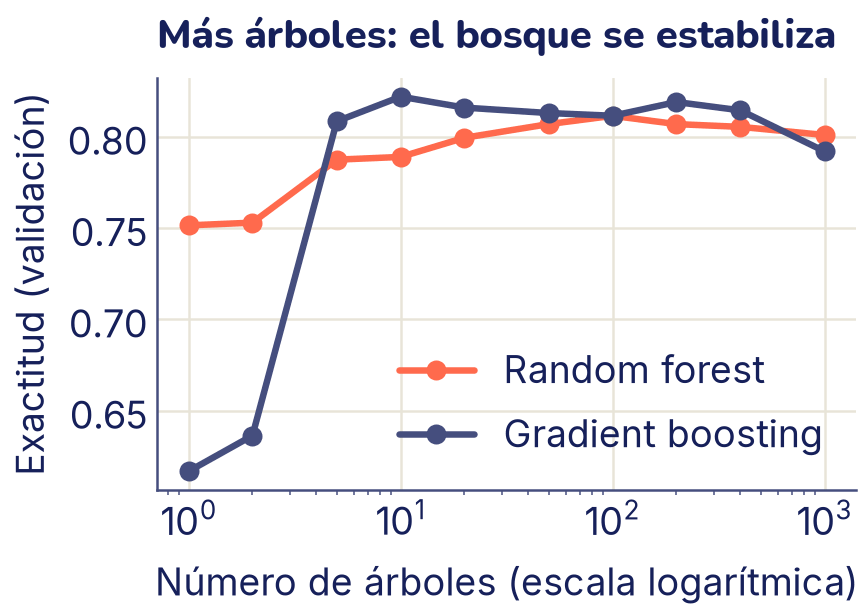

In [ ]:
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import GradientBoostingClassifier

cantidades = [1, 2, 5, 10, 20, 50, 100, 200, 400, 1000]
pliegues = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
acierto_bosque = np.zeros(len(cantidades))
acierto_boost = np.zeros(len(cantidades))
for ent, val in pliegues.split(A, y_arr):
    for i, n in enumerate(cantidades):
        rf = RandomForestClassifier(n_estimators=n, random_state=0)
        rf.fit(A[ent], y_arr[ent])
        acierto_bosque[i] += rf.score(A[val], y_arr[val]) / 5
    gbc = GradientBoostingClassifier(n_estimators=1000, learning_rate=0.1,
                                     max_depth=3, random_state=0)
    gbc.fit(A[ent], y_arr[ent])
    etapas = list(gbc.staged_predict(A[val]))  # tras cada árbol
    for i, n in enumerate(cantidades):
        acierto_boost[i] += np.mean(etapas[n - 1] == y_arr[val]) / 5

for n, b, g in zip(cantidades, acierto_bosque, acierto_boost):
    print(f"{n:4d} árboles:  bosque {b:.3f}   boosting {g:.3f}")

plt.plot(cantidades, acierto_bosque, marker="o", color="C1",
         label="Random forest")
plt.plot(cantidades, acierto_boost, marker="o", color="C2",
         label="Gradient boosting")
plt.xscale("log")
plt.xlabel("Número de árboles (escala logarítmica)")
plt.ylabel("Exactitud (validación)")
plt.title("Más árboles: el bosque se estabiliza")
plt.legend()
plt.show()

Lectura:

- El **bosque** mejora al agregar árboles y después se aplana alrededor de 0,80 y 0,81 (las pequeñas subidas y bajadas son ruido de la validación): agregar árboles no lo hace sobreajustar, solo lo hace más lento. Por eso el número de árboles de un bosque no se «afina»: se pone suficientemente grande.
- El **boosting** con 1 o 2 árboles acierta solo 0,617: es lo que se logra diciendo «murió» para todos, porque con tasa 0,1 las primeras correcciones todavía no alcanzan para cambiar ninguna predicción. Después mejora muy rápido (con 10 árboles ya llega a 0,822, lo más alto) y con cientos de árboles **empeora** (0,792 con 1000): empieza a memorizar el ruido. Su número de árboles sí se elige con validación (o con `early_stopping`, que lo corta solo cuando la validación deja de mejorar).

## HistGradientBoosting, XGBoost y LightGBM

Con miles o millones de filas, `GradientBoostingClassifier` se vuelve lento. **`HistGradientBoostingClassifier`** es una versión moderna de scikit-learn: agrupa cada variable en hasta 255 intervalos (un histograma) y busca los cortes solo entre esos intervalos, lo que lo hace mucho más rápido. Además acepta valores faltantes sin imputar y, por defecto, se detiene solo cuando la validación deja de mejorar si hay más de 10 000 filas.

Fuera de scikit-learn existen **XGBoost** y **LightGBM**, dos librerías de boosting muy usadas en la industria para datos en tablas, con la misma interfaz `fit` y `predict`. En Colab, XGBoost suele venir instalado (`from xgboost import XGBClassifier`); la idea es la misma que acabas de programar.

## Comparar los modelos

Pongamos lado a lado los cuatro modelos del tema, cada uno dentro del pipeline, con validación cruzada sobre el conjunto de entrenamiento.

In [ ]:
from sklearn.ensemble import HistGradientBoostingClassifier

modelos = {
    "Árbol (profundidad 4)": DecisionTreeClassifier(max_depth=4,
                                                    random_state=0),
    "Bagging": BaggingClassifier(DecisionTreeClassifier(),
                                 n_estimators=200, random_state=0),
    "Random forest": RandomForestClassifier(n_estimators=200,
                                            min_samples_leaf=3,
                                            random_state=0),
    "HistGradientBoosting": HistGradientBoostingClassifier(
        max_depth=3, learning_rate=0.05, random_state=0),
}
for nombre, modelo in modelos.items():
    vc = cross_val_score(con_preparacion(modelo), X_ent, y_ent, cv=5)
    print(f"{nombre:22s} {vc.mean():.3f} ± {vc.std():.3f}")

Árbol (profundidad 4)  0.819 ± 0.020
Bagging                0.814 ± 0.025
Random forest          0.819 ± 0.024
HistGradientBoosting   0.820 ± 0.020


Las diferencias son chicas comparadas con cuánto varía la exactitud entre pliegues (el ± es la desviación estándar de los 5 pliegues). Con 668 pasajeros y pocas variables, un árbol bien podado queda casi empatado con los ensambles; en tablas más grandes y con más variables, los ensambles, y sobre todo el boosting, suelen sacar una ventaja clara. Elegimos el random forest, que además es el más estable ante cambios en los datos, y lo medimos **una sola vez** con el conjunto de prueba:

In [ ]:
final = con_preparacion(modelos["Random forest"]).fit(X_ent, y_ent)
print(f"Exactitud en la prueba: {final.score(X_prueba, y_prueba):.3f}")

Exactitud en la prueba: 0.830


Es parecida a la de la validación cruzada; con solo 223 pasajeros de prueba, un par de puntos arriba o abajo es azar. Ese número es el que se reporta: ya no se toca el modelo después de verlo.

## ¿Qué variables importan?

Un bosque de 200 árboles ya no se puede leer pregunta por pregunta. Para saber en qué se apoya se usa la **importancia por permutación**: se toma una columna del conjunto de prueba, se **desordenan** sus valores al azar (así esa columna ya no dice nada de cada pasajero) y se mide cuánto baja la exactitud. Si baja mucho, el modelo dependía de esa variable; si no baja, la ignoraba. Como trabaja con el pipeline completo, mide las columnas originales, antes del one-hot.

sexo             +0.172
clase            +0.070
edad             +0.057
tarifa           +0.034
puerto           +0.030
hermanos_pareja  +0.009
padres_hijos     -0.001


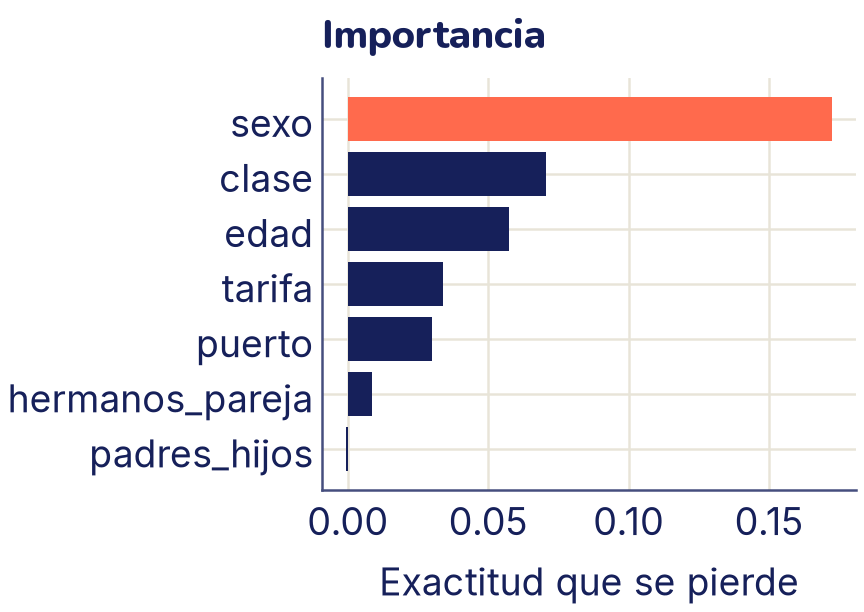

In [ ]:
from sklearn.inspection import permutation_importance

imp = permutation_importance(final, X_prueba, y_prueba, n_repeats=20,
                             random_state=0)
orden = np.argsort(imp.importances_mean)
for j in orden[::-1]:
    print(f"{X.columns[j]:16s} {imp.importances_mean[j]:+.3f}")

colores = ["C1" if j == orden[-1] else "C0" for j in orden]
plt.barh(X.columns[orden], imp.importances_mean[orden], color=colores)
plt.xlabel("Exactitud que se pierde")
plt.title("Importancia")
plt.show()

El sexo es, de lejos, la variable de la que más depende el modelo; después vienen la clase y la edad. Coincide con lo que mostró el árbol de profundidad 2.

Los árboles de scikit-learn también traen `feature_importances_`, una importancia que suma cuánto bajó el Gini en los cortes de cada variable. Es gratis, pero tiene un sesgo: favorece a las variables con muchos valores distintos (como la tarifa o la edad), que ofrecen muchos umbrales para cortar, aunque sea ruido. La importancia por permutación, medida en datos que el modelo no vio, no tiene ese problema; lo vas a comprobar en los ejercicios. Y una advertencia de siempre: una variable importante **ayuda a predecir**; eso no prueba que **cause** el resultado.

## Lo que aprendiste y lo que sigue

- Un **árbol de decisión** predice con preguntas de sí o no encadenadas; divide el espacio en cajas con fronteras en escalera.
- Cada corte se elige de forma voraz: el de mayor **ganancia**, la caída de la impureza de **Gini** (o de la **entropía**) ponderada por el tamaño de cada lado.
- Un árbol sin límites memoriza: se frena con **`max_depth`** y **`min_samples_leaf`**, elegidos con validación cruzada. A los árboles no les importa la escala de las variables.
- Un árbol profundo tiene mucha **varianza**. El **bagging** promedia árboles entrenados con muestras **bootstrap**, y el **random forest** además sortea las variables en cada corte; los dos traen el **error OOB** gratis.
- El **boosting** encadena árboles chicos que corrigen los residuos de los anteriores, como un descenso de gradiente sobre las predicciones; la tasa de aprendizaje y el número de árboles se eligen juntos.
- La **importancia por permutación** dice de qué variables depende un modelo, medida en datos que no vio.

En el tema 12 vas a ver otro modelo clásico, las máquinas de vectores de soporte, que separan las clases con el margen más ancho posible en lugar de con preguntas.

# Ejercicios

## Antes de empezar

Varios ejercicios usan las variables y funciones de la teoría: `X`, `y`, `X_ent`, `X_prueba`, `y_ent`, `y_prueba`, `preparar`, `con_preparacion`, `A` (el entrenamiento ya preparado), `nombres`, `y_arr`, `gini`, `mejor_corte`, `arbol2` (el árbol de profundidad 2) y los datos de la onda (`x`, `onda`, `Xx`). En este cuaderno, ejecuta las celdas de la teoría y trabaja en los ejercicios, que vienen debajo. Intenta cada ejercicio antes de abrir la respuesta.

## Ejercicios

### 1. El Gini de dos cortes, a mano

Diez ejemplos con una sola variable *x* y su clase:

| *x* | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 | 10 |
|---|---|---|---|---|---|---|---|---|---|---|
| clase | 0 | 0 | 0 | 1 | 0 | 1 | 1 | 1 | 1 | 0 |

a) Calcula el Gini del grupo completo.

b) Compara dos cortes: «¿*x* ≤ 3,5?» y «¿*x* ≤ 5,5?». Para cada uno, calcula el Gini de cada lado, el Gini ponderado y la ganancia. ¿Cuál elegiría un árbol?

c) Comprueba tus cuentas con `gini` y busca con `mejor_corte` si hay un corte todavía mejor.

<details>
<summary>Respuesta</summary>

a) Hay 5 ejemplos de cada clase: Gini = 1 − 0,5² − 0,5² = **0,5**.

b) **Corte en 3,5.** A la izquierda quedan 1, 2 y 3, todos de clase 0: Gini = 0. A la derecha quedan 7 ejemplos, 5 de clase 1 y 2 de clase 0: Gini = 1 − (5/7)² − (2/7)² = 1 − 25/49 − 4/49 = 20/49 ≈ 0,408. Ponderado: (3 · 0 + 7 · 0,408) / 10 ≈ **0,286**. Ganancia: 0,5 − 0,286 ≈ **0,214**.

**Corte en 5,5.** A la izquierda, 1 a 5: cuatro de clase 0 y uno de clase 1, Gini = 1 − 0,8² − 0,2² = 0,32. A la derecha, 6 a 10: cuatro de clase 1 y uno de clase 0, también 0,32. Ponderado: **0,32**. Ganancia: **0,18**.

El árbol elegiría el corte en 3,5: deja un lado completamente puro, aunque el otro quede algo mezclado.

c)

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
xs = np.arange(1, 11)
clases = np.array([0, 0, 0, 1, 0, 1, 1, 1, 1, 0])
print(f"Gini total: {gini(clases):.3f}")
for u in [3.5, 5.5]:
    izq, der = clases[xs <= u], clases[xs > u]
    ponderado = (len(izq) * gini(izq) + len(der) * gini(der)) / 10
    print(f"Corte en {u}: izq {gini(izq):.3f}, der {gini(der):.3f},"
          f" ponderado {ponderado:.3f}, ganancia {0.5 - ponderado:.3f}")

u, ganancia, _, _ = mejor_corte(xs, clases)
print(f"Mejor corte: x <= {u}, ganancia {ganancia:.3f}")

<details>
<summary>Respuesta (sigue)</summary>

El mejor corte es el de 3,5. Fíjate que la función solo prueba los puntos medios entre valores vecinos: 1,5, 2,5, 3,5…

</details>

### 2. Entropía y ganancia de información

a) Escribe una función `entropia(etiquetas)` que calcule H = −Σ pₖ · log₂ pₖ. Comprueba que da 0 en un grupo puro y 1 en uno mitad y mitad.

b) Cambia `mejor_corte` para que reciba la medida de impureza como parámetro (`impureza=gini` por defecto) y busca, con la entropía, el mejor corte de la edad entre los hombres del Titanic. ¿Coincide con el de Gini?

In [ ]:
# @title Respuesta: código (doble clic para verlo)
def entropia(etiquetas):
    """Entropía (en bits) de un grupo de etiquetas."""
    _, cuentas = np.unique(etiquetas, return_counts=True)
    p = cuentas / len(etiquetas)
    # 0.0 - ... evita que un grupo puro imprima -0.0
    return 0.0 - np.sum(p * np.log2(p))

def mejor_corte_con(x, etiquetas, impureza=gini):
    """Como mejor_corte, pero con la medida de impureza que se elija."""
    valores = np.unique(x)
    umbrales = (valores[:-1] + valores[1:]) / 2
    n = len(etiquetas)
    ponderadas = np.array([
        (np.sum(x <= u) * impureza(etiquetas[x <= u])
         + np.sum(x > u) * impureza(etiquetas[x > u])) / n
        for u in umbrales])
    k = np.argmin(ponderadas)
    return umbrales[k], impureza(etiquetas) - ponderadas[k]

print("Puro:", entropia([1, 1, 1, 1]), "  mitad:", entropia([0, 1, 0, 1]))
hombres = A[:, list(nombres).index("sexo_mujer")] == 0
edad_h = A[hombres, list(nombres).index("edad")]
for impureza in [gini, entropia]:
    u, g = mejor_corte_con(edad_h, y_arr[hombres], impureza)
    print(f"{impureza.__name__:8s}: edad <= {u:g}, ganancia {g:.3f}")

<details>
<summary>Respuesta</summary>

Las dos medidas eligen el mismo corte. La ganancia de información es un número más grande porque la entropía va de 0 a 1 con dos clases, y el Gini de 0 a 0,5: solo se comparan cortes con la misma medida.

</details>

### 3. Bajar por el árbol

Usa el árbol de profundidad 2 de la teoría (la figura del árbol). Sin computadora, predice si sobrevive cada pasajero y con qué probabilidad:

1. Un niño de 8 años que viajaba en tercera clase.
2. Una mujer de 40 años que viajaba en tercera clase.
3. Un hombre de 30 años que viajaba en primera clase.

Después compruébalo con `arbol2.predict_proba`.

<details>
<summary>Respuesta</summary>

1. No es mujer: va por el sí. Tiene 13 años o menos: va otra vez por el sí y cae en la hoja [0,43, 0,57]. Predicción: **vivió**, con 57 %.
2. Es mujer: va por el no. Su clase es 3, que no es ≤ 2,5: cae en la hoja [0,51, 0,49]. Predicción: **murió**, con 49 % de sobrevivir. Es casi una moneda al aire.
3. No es mujer y tiene más de 13 años: hoja [0,84, 0,16]. Predicción: **murió**, con 16 % de sobrevivir. El árbol de profundidad 2 no mira la clase de los hombres, aunque viajar en primera sí les ayudaba: para eso haría falta un árbol más profundo.

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
pasajeros = pd.DataFrame({
    "clase": [3, 3, 1], "sexo": ["hombre", "mujer", "hombre"],
    "edad": [8, 40, 30], "hermanos_pareja": [0, 0, 0],
    "padres_hijos": [1, 0, 0], "tarifa": [10.0, 10.0, 80.0],
    "puerto": ["S", "S", "S"]})
print(arbol2.predict(pasajeros))
print(arbol2.predict_proba(pasajeros)[:, 1].round(2))

### 4. Un árbol profundo frente a un bosque

La varianza de un modelo se puede medir directamente: entrena el mismo modelo con **dos mitades distintas** del entrenamiento y cuenta en cuántos pasajeros de validación no coinciden sus predicciones.

a) Separa, dentro de `A` y `y_arr`, un 25 % para validación. Divide el resto en dos mitades al azar.

b) Entrena un árbol sin límite de profundidad con cada mitad. ¿En qué porcentaje de los pasajeros de validación discrepan? ¿Qué exactitud tiene cada uno?

c) Repite con dos random forest de 200 árboles. ¿Qué cambia?

In [ ]:
# @title Respuesta: código (doble clic para verlo)
from sklearn.ensemble import RandomForestClassifier

A_resto, A_v, y_resto, y_v = train_test_split(
    A, y_arr, test_size=0.25, stratify=y_arr, random_state=2)
mezcla = np.random.default_rng(3).permutation(len(A_resto))
mitades = [mezcla[: len(mezcla) // 2], mezcla[len(mezcla) // 2:]]

for nombre, crear in [
        ("Árbol profundo", lambda: DecisionTreeClassifier(random_state=0)),
        ("Random forest", lambda: RandomForestClassifier(
            n_estimators=200, random_state=0))]:
    preds = []
    for m in mitades:
        modelo = crear().fit(A_resto[m], y_resto[m])
        preds.append(modelo.predict(A_v))
    aciertos = [np.mean(p == y_v) for p in preds]
    print(f"{nombre:15s} exactitudes {aciertos[0]:.3f} y "
          f"{aciertos[1]:.3f}, discrepan en el "
          f"{np.mean(preds[0] != preds[1]):.0%}")

<details>
<summary>Respuesta</summary>

Con mitades distintas de los datos, los dos árboles profundos no coinciden en más de uno de cada cinco pasajeros de validación: eso es la varianza. Los dos bosques también cambian, pero bastante menos (16 %), y aciertan lo mismo o más. Promediar 200 árboles no elimina la dependencia de los datos, pero la achica.

</details>

### 5. Elegir la profundidad con una búsqueda en rejilla

Con `GridSearchCV` (tema 10) y el pipeline `con_preparacion(DecisionTreeClassifier(random_state=0))`, busca la mejor combinación de `max_depth` (2, 3, 4, 5, 6, 8 y sin límite) y `min_samples_leaf` (1, 3, 5, 10 y 20) con validación cruzada de 5 pliegues. Recuerda que, dentro de un pipeline, los nombres de los hiperparámetros llevan el nombre del paso: `modelo__max_depth`. ¿Cuál es la mejor combinación? ¿Cuántas hojas tiene ese árbol?

In [ ]:
# @title Respuesta: código (doble clic para verlo)
from sklearn.model_selection import GridSearchCV

rejilla = {"modelo__max_depth": [2, 3, 4, 5, 6, 8, None],
           "modelo__min_samples_leaf": [1, 3, 5, 10, 20]}
busqueda = GridSearchCV(
    con_preparacion(DecisionTreeClassifier(random_state=0)),
    rejilla, cv=5)
busqueda.fit(X_ent, y_ent)
print("Mejor combinación:", busqueda.best_params_)
print(f"Validación cruzada: {busqueda.best_score_:.3f}")
mejor_arbol = busqueda.best_estimator_["modelo"]
print("Hojas:", mejor_arbol.get_n_leaves(),
      "  profundidad:", mejor_arbol.get_depth())

<details>
<summary>Respuesta</summary>

La mejor combinación usa los dos frenos a la vez: hasta 8 preguntas, pero con al menos 5 pasajeros por hoja. Con eso llega a 0,829 en validación cruzada, un poco más que con cualquiera de los dos frenos por separado en la teoría. El árbol tiene 52 hojas: ya no se puede leer de un vistazo, que es el precio de dejarlo crecer.

</details>

### 6. La tasa de aprendizaje del boosting

Con los datos de la onda de la teoría, entrena `GradientBoostingRegressor` (100 árboles de profundidad 2) con tasas de aprendizaje 1, 0,1 y 0,01. Para medir cada uno con datos que no vio, genera una segunda onda con otra semilla: `x_nueva = np.sort(np.random.default_rng(1).uniform(0, 6, 80))` y `onda_nueva = np.sin(x_nueva) + ...` con el mismo ruido. Compara el MSE en los datos de entrenamiento y en los nuevos. ¿Qué tasa elegirías? ¿Qué harías con la tasa de 0,01?

In [ ]:
# @title Respuesta: código (doble clic para verlo)
rng_nueva = np.random.default_rng(1)
x_nueva = np.sort(rng_nueva.uniform(0, 6, 80))
onda_nueva = np.sin(x_nueva) + rng_nueva.normal(0, 0.25, 80)

for tasa in [1, 0.1, 0.01]:
    gb = GradientBoostingRegressor(n_estimators=100, learning_rate=tasa,
                                   max_depth=2, random_state=0)
    gb.fit(Xx, onda)
    mse_ent = np.mean((onda - gb.predict(Xx)) ** 2)
    mse_nueva = np.mean((onda_nueva
                         - gb.predict(x_nueva.reshape(-1, 1))) ** 2)
    print(f"tasa {tasa:<4}: entrenamiento {mse_ent:.3f}"
          f"   datos nuevos {mse_nueva:.3f}")

<details>
<summary>Respuesta</summary>

- Con **tasa 1**, el error de entrenamiento llega a cero: cada árbol corrige todo de golpe, incluido el ruido, y en los datos nuevos el error es mayor que con 0,1. Es sobreajuste.
- Con **tasa 0,1**, el error en los datos nuevos es el más bajo. Es la que elegiríamos.
- Con **tasa 0,01**, 100 árboles no alcanzan: el modelo todavía está lejos de la onda en los dos conjuntos (subajuste). Habría que darle muchos más árboles, unas diez veces más. Por eso la tasa y el número de árboles se eligen juntos.

</details>

### 7. Una variable que no sirve para nada

Agrega a los datos una columna de **puro azar**, entrena un random forest y compara las dos importancias: `feature_importances_` (basada en cuánto bajó el Gini) y la importancia por permutación medida en el conjunto de prueba. ¿Qué lugar le da cada una a la columna de azar?

In [ ]:
# @title Respuesta: código (doble clic para verlo)
rng_azar = np.random.default_rng(0)
A_azar = np.column_stack([A, rng_azar.normal(size=len(A))])
A_prueba = preparar.transform(X_prueba)
A_prueba_azar = np.column_stack([A_prueba,
                                 rng_azar.normal(size=len(A_prueba))])
columnas_azar = list(nombres) + ["azar"]

rf = RandomForestClassifier(n_estimators=200, random_state=0)
rf.fit(A_azar, y_arr)
perm = permutation_importance(rf, A_prueba_azar, y_prueba,
                              n_repeats=20, random_state=0)
tabla = pd.DataFrame({"Gini": rf.feature_importances_,
                      "permutación": perm.importances_mean},
                     index=columnas_azar)
print(tabla.sort_values("Gini", ascending=False).round(3))

<details>
<summary>Respuesta</summary>

Para `feature_importances_`, la columna de azar es la **tercera más importante**, por encima de la edad y de la clase. No es que el bosque la use para predecir bien: como tiene 668 valores distintos, ofrece muchísimos umbrales, y en las ramas profundas siempre aparece alguno que «limpia» un poco un grupo chico por pura casualidad. La importancia por permutación, medida en la prueba, le da prácticamente cero (un poco negativa, por el azar del desorden): desordenarla no le quita nada al modelo. La tarifa tiene el mismo problema en menor medida: muchos valores distintos, y una importancia de Gini bastante mayor que la de permutación.

</details>

## Mini-proyecto: el mejor modelo para el Titanic

Busca el mejor modelo de árboles que puedas para predecir quién sobrevivió, y escribe un informe corto de qué variables importan. Usa siempre la misma división de la teoría (`X_ent`, `X_prueba`) y toca el conjunto de prueba **una sola vez**, al final.

**Pasos.**

1. **Nuevas variables.** Agrega a `X` al menos dos: `familia` (hermanos_pareja + padres_hijos + 1) y `cubierta` (la columna `deck` de `titanic`, con los faltantes como la categoría `"desconocida"`). Vuelve a dividir con la misma semilla y la misma estratificación para que los pasajeros de prueba sean los mismos.
2. **Un pipeline nuevo.** Arma otro `ColumnTransformer` que incluya las nuevas columnas.
3. **Busca hiperparámetros** con `GridSearchCV` para un random forest (`min_samples_leaf`, `max_features`) y un `HistGradientBoostingClassifier` (`learning_rate`, `max_depth`). Compara sus puntajes de validación cruzada con el árbol podado del ejercicio 5.
4. **Elige** un modelo según la validación cruzada (no según la prueba) y mídelo una vez en la prueba.
5. **Importancia.** Calcula la importancia por permutación en la prueba y haz el gráfico de barras.
6. **Informe.** Escribe cinco o seis frases: qué modelo elegiste y por qué, cuánto acierta, si las variables nuevas ayudaron y qué variables importan. Agrega una advertencia: ¿qué no dice la importancia?

<details>
<summary>Resultados de referencia, para comprobar los tuyos</summary>

Este código hace los pasos 1 a 5 (sin el gráfico); tus números deberían coincidir si usas las mismas rejillas.

</details>

In [ ]:
# @title Resultados de referencia, para comprobar los tuyos: código (doble clic para verlo)
from sklearn.ensemble import HistGradientBoostingClassifier

# Paso 1: nuevas variables
X_mas = X.copy()
X_mas["familia"] = X["hermanos_pareja"] + X["padres_hijos"] + 1
cubierta = titanic["deck"].astype(str)
X_mas["cubierta"] = cubierta.where(titanic["deck"].notna(), "desconocida")
Xm_ent, Xm_prueba, _, _ = train_test_split(
    X_mas, y, test_size=0.25, stratify=y, random_state=0)
print("Mismos pasajeros de prueba:",
      (Xm_prueba.index == X_prueba.index).all())

# Paso 2: el pipeline con las columnas nuevas
preparar_mas = ColumnTransformer(
    [("num", SimpleImputer(strategy="median"), numericas + ["familia"]),
     ("cat", categoricas_a_numeros, categoricas + ["cubierta"])],
    verbose_feature_names_out=False)

# Paso 3: búsqueda para cada modelo
candidatos = {
    "Random forest": (
        RandomForestClassifier(n_estimators=300, random_state=0),
        {"modelo__min_samples_leaf": [1, 3, 5],
         "modelo__max_features": ["sqrt", 0.5]}),
    "HistGradientBoosting": (
        HistGradientBoostingClassifier(random_state=0),
        {"modelo__learning_rate": [0.03, 0.1],
         "modelo__max_depth": [2, 3, None]}),
}
mejores = {}
for nombre, (modelo, rejilla_m) in candidatos.items():
    tubo = Pipeline([("preparar", preparar_mas), ("modelo", modelo)])
    b = GridSearchCV(tubo, rejilla_m, cv=5).fit(Xm_ent, y_ent)
    mejores[nombre] = b
    elegidos = {k.split("__")[1]: v for k, v in b.best_params_.items()}
    print(f"{nombre:21s} {b.best_score_:.3f}  {elegidos}")

# Paso 4: el mejor según la validación cruzada, medido una vez
elegido = max(mejores, key=lambda k: mejores[k].best_score_)
modelo_final = mejores[elegido].best_estimator_
print(f"Elegido: {elegido}. Exactitud en la prueba: "
      f"{modelo_final.score(Xm_prueba, y_prueba):.3f}")

# Paso 5: importancia por permutación en la prueba
imp_mas = permutation_importance(modelo_final, Xm_prueba, y_prueba,
                                 n_repeats=20, random_state=0)
print(pd.Series(imp_mas.importances_mean, index=X_mas.columns)
      .sort_values(ascending=False).round(3).to_string())

<details>
<summary>Resultados de referencia, para comprobar los tuyos (sigue)</summary>

Un informe posible:

- El random forest (300 árboles, al menos 3 pasajeros por hoja y la mitad de las variables en cada corte) tuvo la mejor validación cruzada, 0,840, apenas por encima del HistGradientBoosting (0,832) y del árbol podado (0,829). Con tan pocos pasajeros, esas diferencias están dentro del ruido.
- En la prueba acertó 0,825, en línea con la validación cruzada. Es el número que se reporta.
- Las variables nuevas no ayudaron: la cubierta casi no importa, y `familia` sale un poco negativa: desordenarla no empeora el modelo, probablemente porque repite lo que ya dicen `hermanos_pareja` y `padres_hijos`. La mejora de la validación cruzada respecto de la teoría viene sobre todo de afinar los hiperparámetros, no de las columnas nuevas. Una variable nueva no ayuda solo por existir: hay que medirla.
- El sexo es, de lejos, la variable más importante; después vienen la edad y la clase.
- La importancia dice de qué depende este modelo para predecir, no por qué sobrevivió cada persona. Además, entre variables que dicen casi lo mismo (como `familia` y sus dos componentes), la importancia se reparte y cada una parece menos importante de lo que es.

</details>

## Errores comunes

- **Dejar crecer el árbol sin límites.** Acierta casi el 100 % en entrenamiento y menos que un árbol podado en validación. Elige `max_depth` o `min_samples_leaf` con validación cruzada.
- **Escalar o estandarizar «por costumbre» antes de un árbol.** No hace daño, pero no cambia nada: los cortes dependen solo del orden de los valores.
- **Codificar una categoría nominal con números** (Cherbourg = 1, Queenstown = 2, Southampton = 3). El árbol puede preguntar «¿puerto ≤ 1,5?» como si hubiera un orden que no existe. Usa one-hot, como en el tema 10.
- **Afinar el número de árboles de un random forest como si fuera a sobreajustar.** En el bosque, más árboles solo cuesta tiempo; en el boosting sí hay que elegirlo, junto con la tasa de aprendizaje.
- **Subir la tasa de aprendizaje del boosting para «ir más rápido».** Con tasa 1, cada árbol corrige todo de golpe, incluido el ruido.
- **Leer `feature_importances_` como la verdad.** Favorece a las variables con muchos valores distintos, aunque sean ruido. Usa la importancia por permutación en datos que el modelo no vio.
- **Creer que una variable importante es una causa.** El modelo encontró que ayuda a predecir en estos datos; eso no dice por qué.
- **Comparar modelos con el conjunto de prueba.** Se comparan con validación cruzada sobre el entrenamiento; la prueba se usa una vez, con el modelo ya elegido.
- **Confiar en un árbol leído de memoria.** Un árbol profundo cambia mucho si cambian un poco los datos: sus preguntas de abajo no son reglas generales.

## ¿Lo lograste?

Al terminar este tema deberías poder hacer lo siguiente. Al lado, dónde lo practicaste.

- Explicar cómo un árbol elige un corte con la impureza de Gini o la entropía (ejercicios 1 y 2, y la actividad).
- Controlar el sobreajuste de un árbol con `max_depth` y `min_samples_leaf` (ejercicio 5).
- Explicar el bagging y el random forest como el promedio de árboles distintos (ejercicio 4).
- Explicar el gradient boosting como una corrección sucesiva de errores (ejercicio 6).
- Comparar los modelos e interpretar la importancia de las variables (ejercicio 7 y el mini-proyecto).